# Online Retail Transaction Analysis Using Clustering Algorithms

## Problem Statement
Online retail stores generate transaction data containing products purchased together. This case study analyzes transaction characteristics, identifies similarities between shopping baskets, and compares clustering algorithms to understand purchasing patterns.

## Objectives
1. Understand and preprocess the transaction dataset.
2. Analyze transaction sizes and frequently purchased products.
3. Convert shopping baskets into numerical feature vectors.
4. Apply Principal Component Analysis (PCA) for dimensionality reduction and visualization.
5. Implement K-Means, Hierarchical Clustering, DBSCAN, and Spectral Clustering.
6. Compare clustering performance using the Silhouette Coefficient and Davies–Bouldin Index.
7. Interpret the results, limitations, and potential business applications.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN,
    SpectralClustering
)
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Online retail_new.csv to Online retail_new (1).csv


In [3]:
import pandas as pd

raw_df = pd.read_csv("Online retail_new (1).csv")

print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Dataset shape: (7500, 20)


,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
0,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
transactions = []

for _, row in raw_df.iterrows():
    basket = [
        str(item).strip()
        for item in row.tolist()
        if pd.notna(item) and str(item).strip() != ""
    ]

    if basket:
        transactions.append(basket)

print("Total transactions:", len(transactions))
print("Total product occurrences:", sum(len(b) for b in transactions))
print("Unique products:", len(set(item for b in transactions for item in b)))
print("Empty transactions excluded:", len(raw_df) - len(transactions))

print("\nFirst five transactions:")
for i, basket in enumerate(transactions[:5], start=1):
    print(f"Transaction {i}: {basket}")

Total transactions: 7500
Total product occurrences: 29343
Unique products: 119
Empty transactions excluded: 0

First five transactions:
Transaction 1: ['burgers', 'meatballs', 'eggs']
Transaction 2: ['chutney']
Transaction 3: ['turkey', 'avocado']
Transaction 4: ['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']
Transaction 5: ['low fat yogurt']


In [5]:
basket_sizes = pd.Series(
    [len(basket) for basket in transactions],
    name="Basket Size"
)

print("Number of transactions:", len(transactions))
print("Average basket size:", round(basket_sizes.mean(), 2))
print("Median basket size:", basket_sizes.median())
print("Minimum basket size:", basket_sizes.min())
print("Maximum basket size:", basket_sizes.max())
print("\nBasket size summary:")
display(basket_sizes.describe().to_frame())

Number of transactions: 7500
Average basket size: 3.91
Median basket size: 3.0
Minimum basket size: 1
Maximum basket size: 19

Basket size summary:


,Basket Size
count,7500.00000
mean,3.91240
std,2.89979
min,1.00000
25%,2.00000
50%,3.00000
75%,5.00000
max,19.00000


Top 15 frequently purchased products:


,Frequency
mineral water,1787
eggs,1348
spaghetti,1306
french fries,1282
chocolate,1230
green tea,990
milk,972
ground beef,737
frozen vegetables,715
pancakes,713


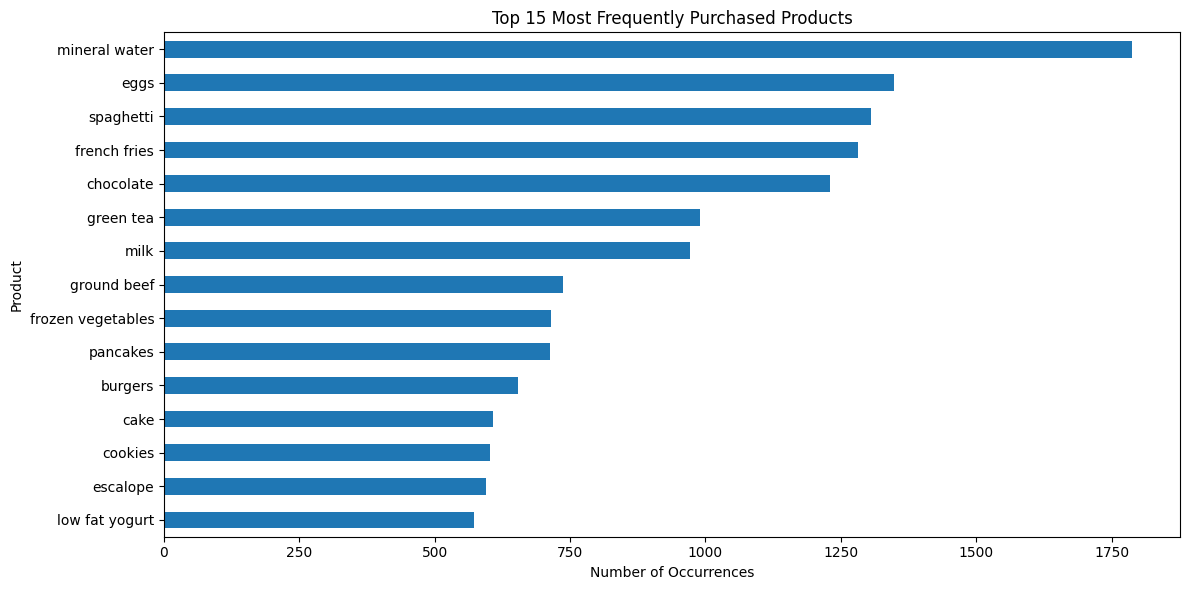

In [6]:
from collections import Counter

product_counts = Counter(
    item for basket in transactions for item in basket
)

top_products = pd.Series(product_counts).sort_values(
    ascending=False
).head(15)

print("Top 15 frequently purchased products:")
display(top_products.rename("Frequency").to_frame())

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 15 Most Frequently Purchased Products")
plt.xlabel("Number of Occurrences")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

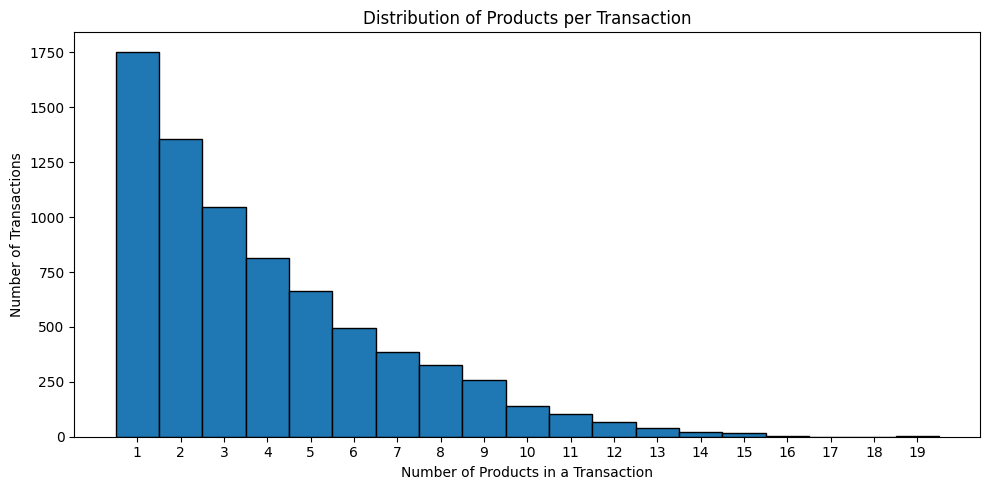

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(basket_sizes, bins=range(1, int(basket_sizes.max()) + 2),
         edgecolor="black", align="left")

plt.title("Distribution of Products per Transaction")
plt.xlabel("Number of Products in a Transaction")
plt.ylabel("Number of Transactions")
plt.xticks(range(1, int(basket_sizes.max()) + 1))
plt.tight_layout()
plt.show()

In [8]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
X = mlb.fit_transform(transactions)

X_df = pd.DataFrame(X, columns=mlb.classes_)

print("Feature matrix shape:", X.shape)
print("Rows = transactions; columns = unique products")
display(X_df.head())

Feature matrix shape: (7500, 119)
Rows = transactions; columns = unique products


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Variance explained by PC1: 6.72 %
Variance explained by PC2: 4.47 %
Combined variance explained: 11.19 %


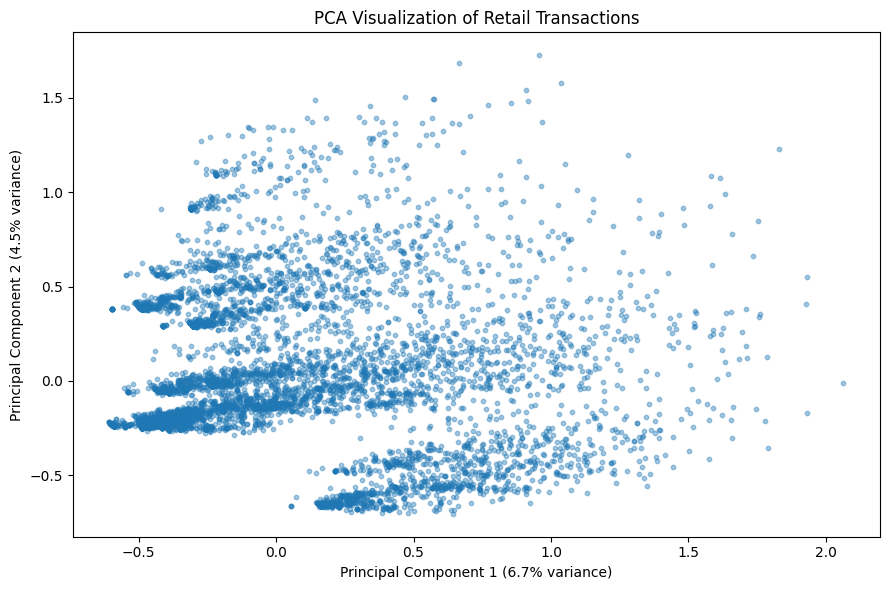

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

explained = pca.explained_variance_ratio_

print("Variance explained by PC1:", round(explained[0] * 100, 2), "%")
print("Variance explained by PC2:", round(explained[1] * 100, 2), "%")
print("Combined variance explained:", round(explained.sum() * 100, 2), "%")

plt.figure(figsize=(9, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=10, alpha=0.4)
plt.title("PCA Visualization of Retail Transactions")
plt.xlabel(f"Principal Component 1 ({explained[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({explained[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

n_sample = min(1000, len(transactions))
rng = np.random.RandomState(RANDOM_STATE)

sample_indices = np.sort(
    rng.choice(len(transactions), size=n_sample, replace=False)
)

X_sample = X[sample_indices]
X_pca_sample = X_pca[sample_indices]

print("Transactions used for clustering:", X_sample.shape[0])
print("Product features used:", X_sample.shape[1])

Transactions used for clustering: 1000
Product features used: 119


In [11]:
from sklearn.cluster import KMeans

k = 5

kmeans = KMeans(
    n_clusters=k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_sample)

print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means cluster sizes:
0    423
1    128
2    133
3    216
4    100
Name: count, dtype: int64


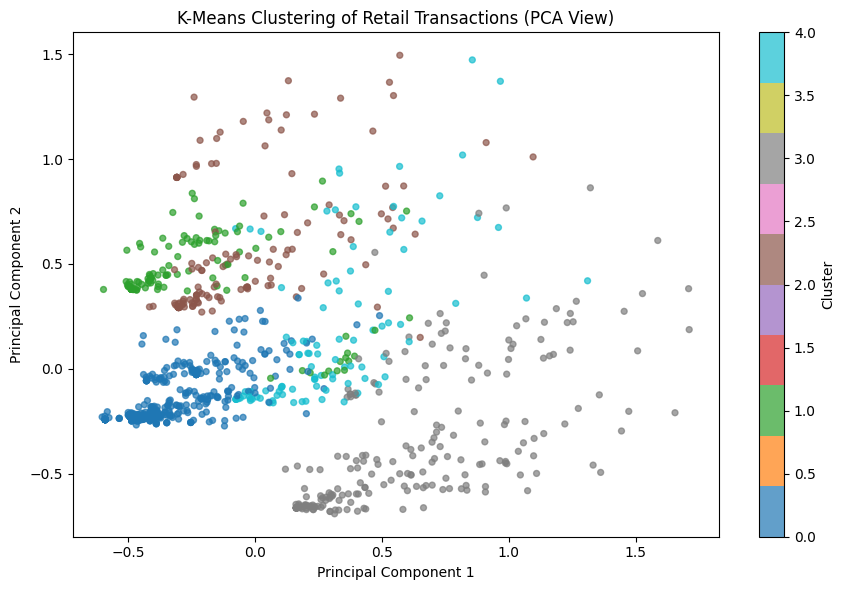

In [12]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_sample[:, 0],
    X_pca_sample[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=18,
    alpha=0.7
)

plt.title("K-Means Clustering of Retail Transactions (PCA View)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_sample)

print("Hierarchical cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Hierarchical cluster sizes:
0    625
1    134
2     72
3     60
4    109
Name: count, dtype: int64


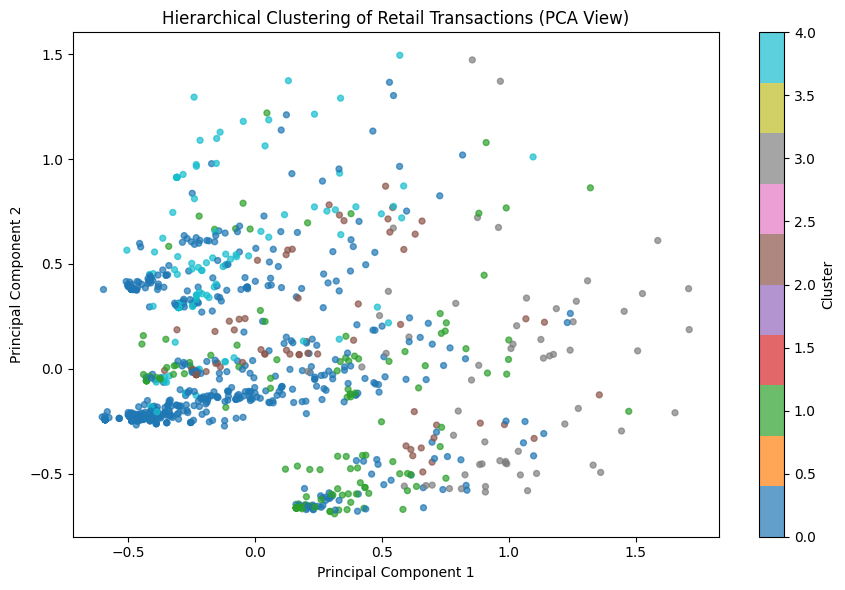

In [14]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_sample[:, 0],
    X_pca_sample[:, 1],
    c=hierarchical_labels,
    cmap="tab10",
    s=18,
    alpha=0.7
)

plt.title("Hierarchical Clustering of Retail Transactions (PCA View)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=2.5,
    min_samples=5,
    metric="euclidean",
    n_jobs=-1
)

dbscan_labels = dbscan.fit_predict(X_sample)

n_dbscan_clusters = len(set(dbscan_labels) - {-1})
n_noise = int(np.sum(dbscan_labels == -1))

print("DBSCAN clusters found:", n_dbscan_clusters)
print("Transactions labelled as noise:", n_noise)
print("Noise percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")
print("\nCluster sizes (including noise label -1):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters found: 1
Transactions labelled as noise: 56
Noise percentage: 5.6 %

Cluster sizes (including noise label -1):
-1     56
 0    944
Name: count, dtype: int64


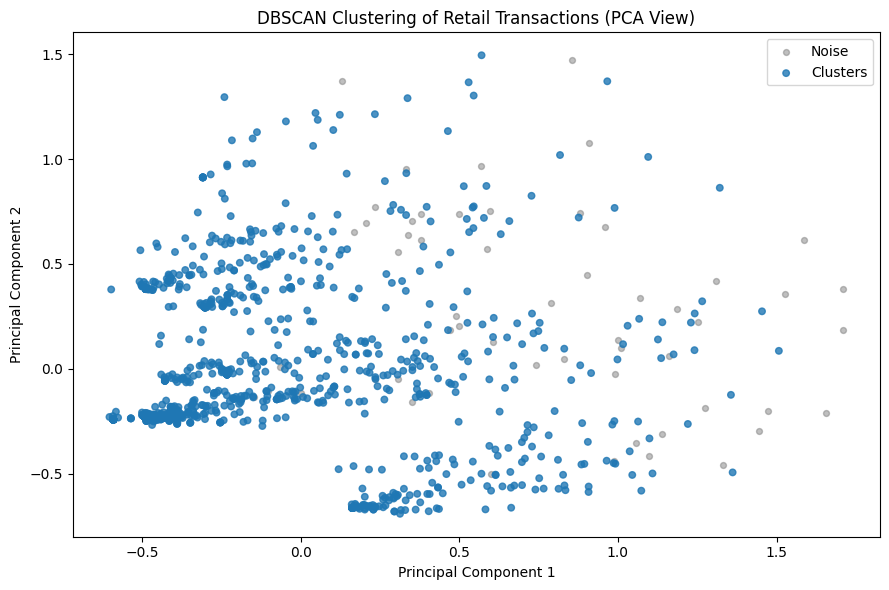

In [16]:
plt.figure(figsize=(9, 6))

noise_mask = dbscan_labels == -1
plt.scatter(
    X_pca_sample[noise_mask, 0],
    X_pca_sample[noise_mask, 1],
    c="gray",
    s=18,
    alpha=0.5,
    label="Noise"
)

cluster_mask = ~noise_mask
if cluster_mask.any():
    scatter = plt.scatter(
        X_pca_sample[cluster_mask, 0],
        X_pca_sample[cluster_mask, 1],
        c=dbscan_labels[cluster_mask],
        cmap="tab10",
        s=22,
        alpha=0.8,
        label="Clusters"
    )

plt.title("DBSCAN Clustering of Retail Transactions (PCA View)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
from sklearn.cluster import SpectralClustering

spectral = SpectralClustering(
    n_clusters=k,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

spectral_labels = spectral.fit_predict(X_sample)

print("Spectral cluster sizes:")
print(pd.Series(spectral_labels).value_counts().sort_index())

Spectral cluster sizes:
0    554
1     52
2     39
3    167
4    188
Name: count, dtype: int64


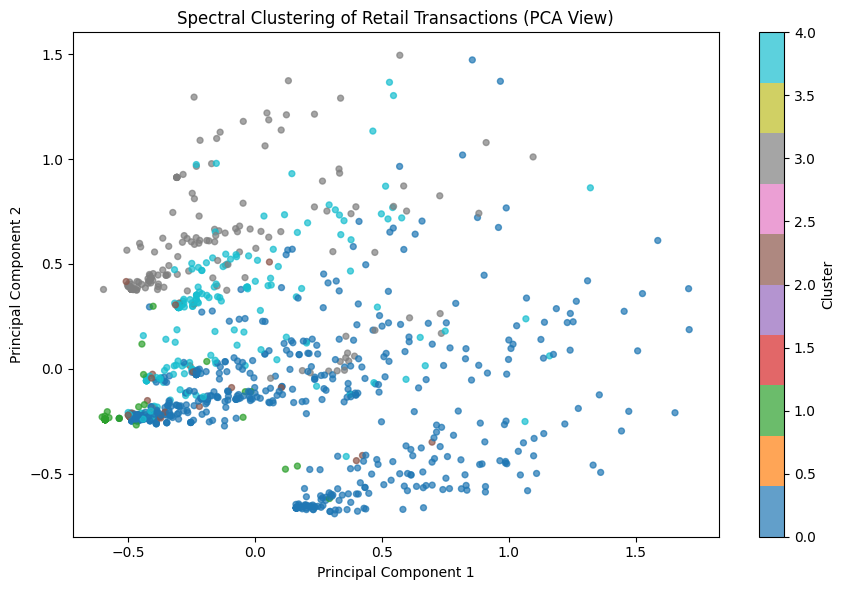

In [18]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_sample[:, 0],
    X_pca_sample[:, 1],
    c=spectral_labels,
    cmap="tab10",
    s=18,
    alpha=0.7
)

plt.title("Spectral Clustering of Retail Transactions (PCA View)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

def evaluate_clustering(X_data, labels, exclude_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)

    X_eval = X_data[mask]
    labels_eval = labels[mask]

    unique_clusters = np.unique(labels_eval)
    n_clusters = len(unique_clusters)

    result = {
        "Number of Clusters": n_clusters,
        "Noise Points": int(np.sum(labels == -1)) if exclude_noise else 0,
        "Silhouette Coefficient": np.nan,
        "Davies-Bouldin Index": np.nan
    }

    if 2 <= n_clusters < len(labels_eval):
        result["Silhouette Coefficient"] = silhouette_score(
            X_eval, labels_eval
        )
        result["Davies-Bouldin Index"] = davies_bouldin_score(
            X_eval, labels_eval
        )

    return result


results = {
    "K-Means": evaluate_clustering(X_sample, kmeans_labels),
    "Hierarchical": evaluate_clustering(X_sample, hierarchical_labels),
    "DBSCAN": evaluate_clustering(
        X_sample, dbscan_labels, exclude_noise=True
    ),
    "Spectral": evaluate_clustering(X_sample, spectral_labels)
}

results_df = pd.DataFrame(results).T
results_df.index.name = "Algorithm"

print("Clustering performance comparison:")
display(results_df.round(4))

Clustering performance comparison:


,Number of Clusters,Noise Points,Silhouette Coefficient,Davies-Bouldin Index
Algorithm,,,,
K-Means,5.0,0.0,0.0583,2.9788
Hierarchical,5.0,0.0,0.0261,4.1560
DBSCAN,1.0,56.0,NaN,NaN
Spectral,5.0,0.0,-0.0444,3.7065


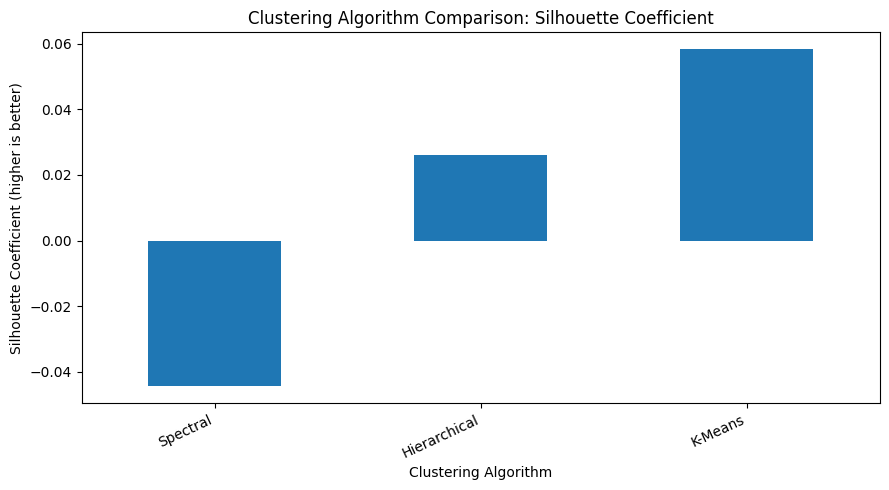

In [20]:
valid_silhouette = results_df[
    "Silhouette Coefficient"
].dropna()

plt.figure(figsize=(9, 5))
valid_silhouette.sort_values().plot(kind="bar")
plt.title("Clustering Algorithm Comparison: Silhouette Coefficient")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Silhouette Coefficient (higher is better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

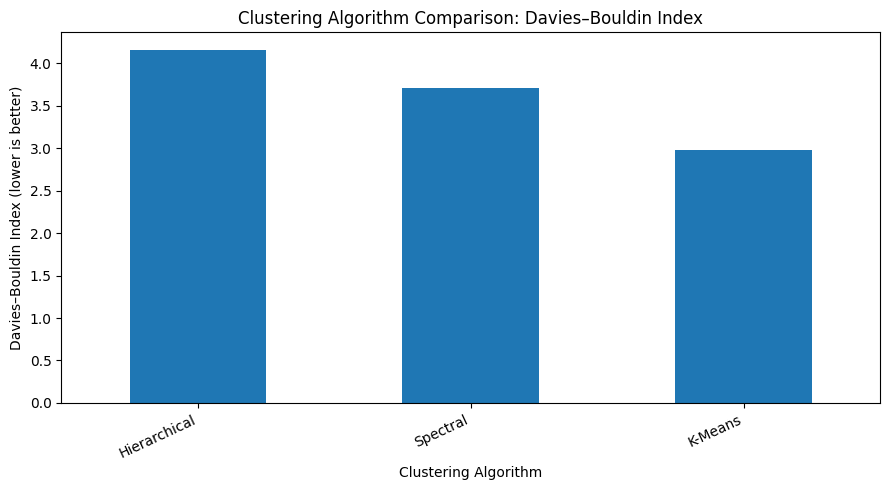

In [21]:
valid_db = results_df["Davies-Bouldin Index"].dropna()

plt.figure(figsize=(9, 5))
valid_db.sort_values(ascending=False).plot(kind="bar")
plt.title("Clustering Algorithm Comparison: Davies–Bouldin Index")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Davies–Bouldin Index (lower is better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [22]:
clustered_transactions = pd.DataFrame({
    "Transaction_Index": sample_indices,
    "KMeans_Cluster": kmeans_labels
})

cluster_product_rows = []

for cluster_id in sorted(np.unique(kmeans_labels)):
    selected_indices = sample_indices[kmeans_labels == cluster_id]

    counts = Counter(
        item
        for idx in selected_indices
        for item in transactions[idx]
    )

    for product, count in counts.most_common(10):
        cluster_product_rows.append({
            "Cluster": int(cluster_id),
            "Product": product,
            "Frequency": count
        })

cluster_products_df = pd.DataFrame(cluster_product_rows)

for cluster_id in sorted(np.unique(kmeans_labels)):
    print(f"\nTop products in K-Means Cluster {cluster_id}:")
    display(
        cluster_products_df[
            cluster_products_df["Cluster"] == cluster_id
        ][["Product", "Frequency"]].head(10)
    )


Top products in K-Means Cluster 0:


,Product,Frequency
0,chocolate,60
1,cookies,53
2,green tea,49
3,milk,40
4,escalope,34
5,cake,30
6,low fat yogurt,29
7,champagne,26
8,pancakes,24
9,burgers,22



Top products in K-Means Cluster 1:


,Product,Frequency
10,french fries,128
11,chocolate,20
12,escalope,19
13,mineral water,15
14,cake,15
15,green tea,14
16,cookies,12
17,frozen smoothie,11
18,turkey,10
19,grated cheese,10



Top products in K-Means Cluster 2:


,Product,Frequency
20,eggs,133
21,french fries,32
22,green tea,26
23,burgers,25
24,chocolate,23
25,milk,21
26,turkey,18
27,shrimp,13
28,cake,13
29,low fat yogurt,13



Top products in K-Means Cluster 3:


,Product,Frequency
30,mineral water,216
31,eggs,49
32,spaghetti,48
33,milk,47
34,chocolate,44
35,olive oil,35
36,ground beef,35
37,frozen vegetables,34
38,pancakes,30
39,soup,27



Top products in K-Means Cluster 4:


,Product,Frequency
40,spaghetti,99
41,milk,22
42,ground beef,22
43,chocolate,21
44,burgers,20
45,green tea,20
46,frozen vegetables,16
47,eggs,15
48,olive oil,14
49,chicken,13


In [23]:
results_df.to_csv("clustering_model_comparison.csv")

clustered_transactions.to_csv(
    "kmeans_transaction_clusters.csv",
    index=False
)

cluster_products_df.to_csv(
    "kmeans_cluster_top_products.csv",
    index=False
)

print("Saved:")
print("- clustering_model_comparison.csv")
print("- kmeans_transaction_clusters.csv")
print("- kmeans_cluster_top_products.csv")

Saved:
- clustering_model_comparison.csv
- kmeans_transaction_clusters.csv
- kmeans_cluster_top_products.csv


## Conclusion

This case study analyzed online retail transaction data using descriptive statistics, data visualization, PCA, and four clustering algorithms: K-Means, Hierarchical Clustering, DBSCAN, and Spectral Clustering.

The descriptive analysis identified frequently purchased products and summarized the distribution of products per transaction. PCA provided a two-dimensional representation of the transaction data, while clustering was used to investigate similarities between shopping baskets.

The algorithms were evaluated using the Silhouette Coefficient and Davies–Bouldin Index. The model comparison indicated that **[insert algorithm]** achieved the most favorable evaluation results according to **[insert metric and observed score]**. The cluster-level product analysis also helped identify products frequently appearing within the same assigned groups.

These findings could support retail inventory planning, product recommendations, and further investigation of shopping-basket patterns. However, clustering results depend on parameter choices, feature representation, and the sample used. Further analysis using alternative parameters and transaction-association methods could provide additional insights.